# Step 0: Project Setup

## Imports

In [1]:
import os
import zipfile
import shutil
import random
import numpy as np
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import StepLR
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, ConcatDataset
from sklearn.metrics import precision_recall_fscore_support, accuracy_score, confusion_matrix
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
from sklearn.manifold import TSNE
import torch.nn.functional as F
import pandas as pd
import gc

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

## Fix random seeds

In [2]:
seed = 5

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    
# Ensure deterministic behavior in PyTorch convolutions
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print(f"[*] Random seed fixed to {seed}")

[*] Random seed fixed to 5


## Create project folders

In [3]:
base_path = "."
folders = ['data', 'models', 'logs', 'plots']
for folder in folders:
    folder_path = os.path.join(base_path, folder)
    os.makedirs(folder_path, exist_ok=True)
    print(f"[*] Created/Verified directory: {folder_path}/")

[*] Created/Verified directory: .\data/
[*] Created/Verified directory: .\models/
[*] Created/Verified directory: .\logs/
[*] Created/Verified directory: .\plots/


## Unzip Dataset + Restructure Folders

In [4]:
zip_path = 'archive.zip'
target_dir='data/fish_dataset'

if not os.path.exists(zip_path):
    print(f"[!] Error: {zip_path} not found.")
    exit()

# Create clean target directory
if os.path.exists(target_dir):
    shutil.rmtree(target_dir)
os.makedirs(target_dir, exist_ok=True)

print(f"[*] Extracting {zip_path}...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('temp_extracted')

# Dataset specified path: Fish_Dataset/Fish_Dataset/Class/Class/
# Need to move files to: data/fish_dataset/Class/
base_source = Path('temp_extracted/Fish_Dataset/Fish_Dataset')

print("[*] Restructuring folders...")
# Iterate through each seafood class folder
for class_folder in base_source.iterdir():
    if class_folder.is_dir():
        class_name = class_folder.name
        # Path to the actual images nested inside
        deep_path = class_folder / class_name
        
        if deep_path.exists():
            dest_path = Path(target_dir) / class_name
            os.makedirs(dest_path, exist_ok=True)
            
            # Move all .png files
            for img in deep_path.glob('*.png'):
                shutil.move(str(img), str(dest_path / img.name))
        
# Cleanup: Delete the messy temp folder
shutil.rmtree('temp_extracted')
print(f"[*] Cleanup complete. Dataset organized in '{target_dir}'")

[*] Extracting archive.zip...
[*] Restructuring folders...
[*] Cleanup complete. Dataset organized in 'data/fish_dataset'


## Record dataset metrics

In [5]:
data_path = 'data/fish_dataset'

class_counts = {}
path = Path(data_path)

for class_dir in sorted(path.iterdir()):
    if class_dir.is_dir():
        count = len(list(class_dir.glob('*.png')))
        class_counts[class_dir.name] = count

if not class_counts:
    print("[!] No classes found.")
    exit()

print("\n" + "="*30)
print("      DATASET METRICS")
print("="*30)
max_count = max(class_counts.values())

# Ratio is class imbalance ratio, but all classes have same number so all will be 1.0
for label, count in class_counts.items():
    ratio = max_count / count if count > 0 else 0
    print(f"{label:<20} | Images: {count:<5} | Ratio: {ratio:.2f}")
print("="*30)


      DATASET METRICS
Black Sea Sprat      | Images: 1000  | Ratio: 1.00
Gilt-Head Bream      | Images: 1000  | Ratio: 1.00
Hourse Mackerel      | Images: 1000  | Ratio: 1.00
Red Mullet           | Images: 1000  | Ratio: 1.00
Red Sea Bream        | Images: 1000  | Ratio: 1.00
Sea Bass             | Images: 1000  | Ratio: 1.00
Shrimp               | Images: 1000  | Ratio: 1.00
Striped Red Mullet   | Images: 1000  | Ratio: 1.00
Trout                | Images: 1000  | Ratio: 1.00


# Step 1: Dataset Preparation

## Train / Val / Test & AL Pool Split

In [6]:
def create_al_splits(source_dir='data/fish_dataset', target_dir='data/al_splits'):
    source_path = Path(source_dir)
    if not source_path.exists():
        print(f"[!] Error: Source directory '{source_dir}' not found.")
        exit()

    # Define our new directory structure
    splits = ['test', 'val', 'train_labeled', 'train_unlabeled']

    print("[*] Creating split directories...")
    # Clean slate if the directory already exists
    if os.path.exists(target_dir):
        shutil.rmtree(target_dir)
        
    for split in splits:
        os.makedirs(Path(target_dir) / split, exist_ok=True)

    print("[*] Partitioning data...")

    classes = [d.name for d in source_path.iterdir() if d.is_dir()]

    for class_name in sorted(classes):
        # Create class subfolders in each split
        for split in splits:
            os.makedirs(Path(target_dir) / split / class_name, exist_ok=True)

        # Get all images for the class and shuffle
        class_path = source_path / class_name
        images = sorted(list(class_path.glob('*.png')))
        random.shuffle(images)

        # Calculate indices based on exact counts (1000 total per class)
        # Test: 20%, Val: 10%, Train Pool: 70% (10 labeled, rest unlabeled)
        test_imgs = images[:200]
        val_imgs = images[200:300]
        train_labeled_imgs = images[300:310]
        train_unlabeled_imgs = images[310:]

        # Helper function to copy lists of files
        def copy_files(file_list, dest_split):
            dest_dir = Path(target_dir) / dest_split / class_name
            for img_path in file_list:
                shutil.copy(str(img_path), str(dest_dir / img_path.name))

        # Execute copying
        copy_files(test_imgs, 'test')
        copy_files(val_imgs, 'val')
        copy_files(train_labeled_imgs, 'train_labeled')
        copy_files(train_unlabeled_imgs, 'train_unlabeled')

    print(f"[*] Data successfully partitioned into '{target_dir}'")

if __name__ == "__main__":
    create_al_splits()

[*] Creating split directories...
[*] Partitioning data...
[*] Data successfully partitioned into 'data/al_splits'


## Record Metrics & Plot Distributions

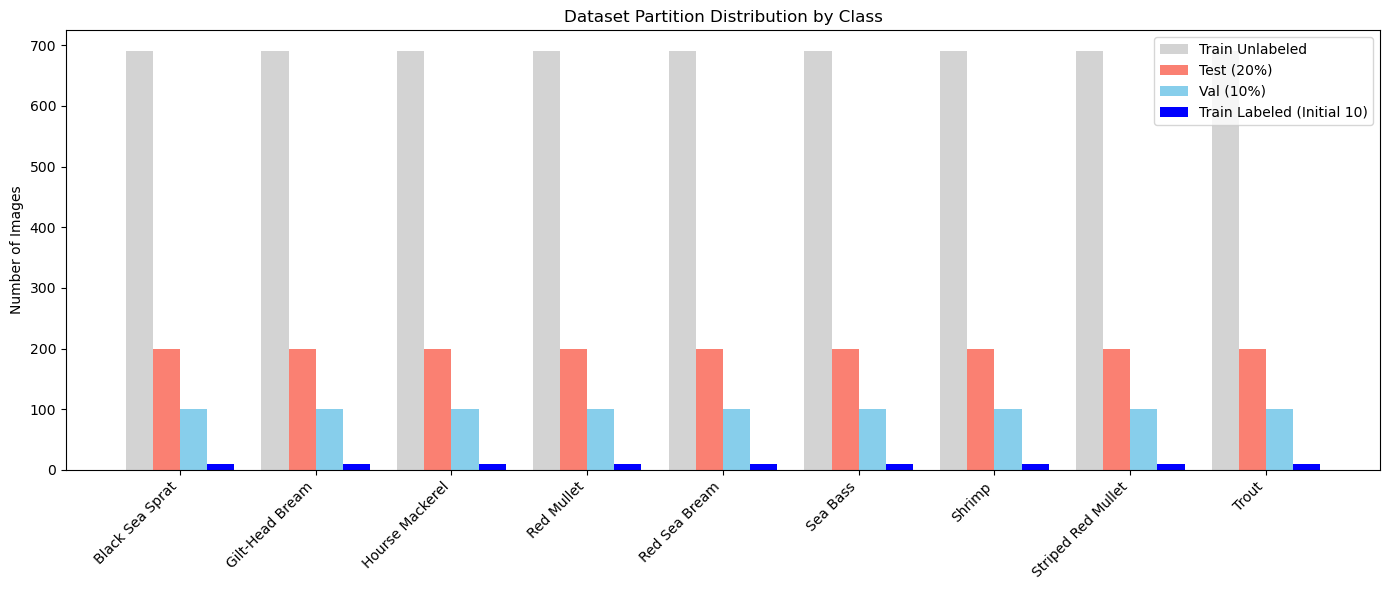

In [7]:
def plot_class_distribution(target_dir='data/al_splits'):
    target_path = Path(target_dir)
    splits = ['train_labeled', 'train_unlabeled', 'val', 'test']

    if not target_path.exists():
        exit()

    classes = sorted([d.name for d in (target_path / 'test').iterdir() if d.is_dir()])

    # Gather counts
    counts = {split: [] for split in splits}
    for split in splits:
        for class_name in classes:
            split_class_dir = target_path / split / class_name
            num_images = len(list(split_class_dir.glob('*.png')))
            counts[split].append(num_images)

    # Plotting
    x = np.arange(len(classes))
    width = 0.2

    fig, ax = plt.subplots(figsize=(14, 6))

    ax.bar(x - 1.5*width, counts['train_unlabeled'], width, label='Train Unlabeled', color='lightgray')
    ax.bar(x - 0.5*width, counts['test'], width, label='Test (20%)', color='salmon')
    ax.bar(x + 0.5*width, counts['val'], width, label='Val (10%)', color='skyblue')
    ax.bar(x + 1.5*width, counts['train_labeled'], width, label='Train Labeled (Initial 10)', color='blue')

    ax.set_ylabel('Number of Images')
    ax.set_title('Dataset Partition Distribution by Class')
    ax.set_xticks(x)
    ax.set_xticklabels(classes, rotation=45, ha='right')
    ax.legend()

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    plot_class_distribution()

## Qualitative Sanity Check

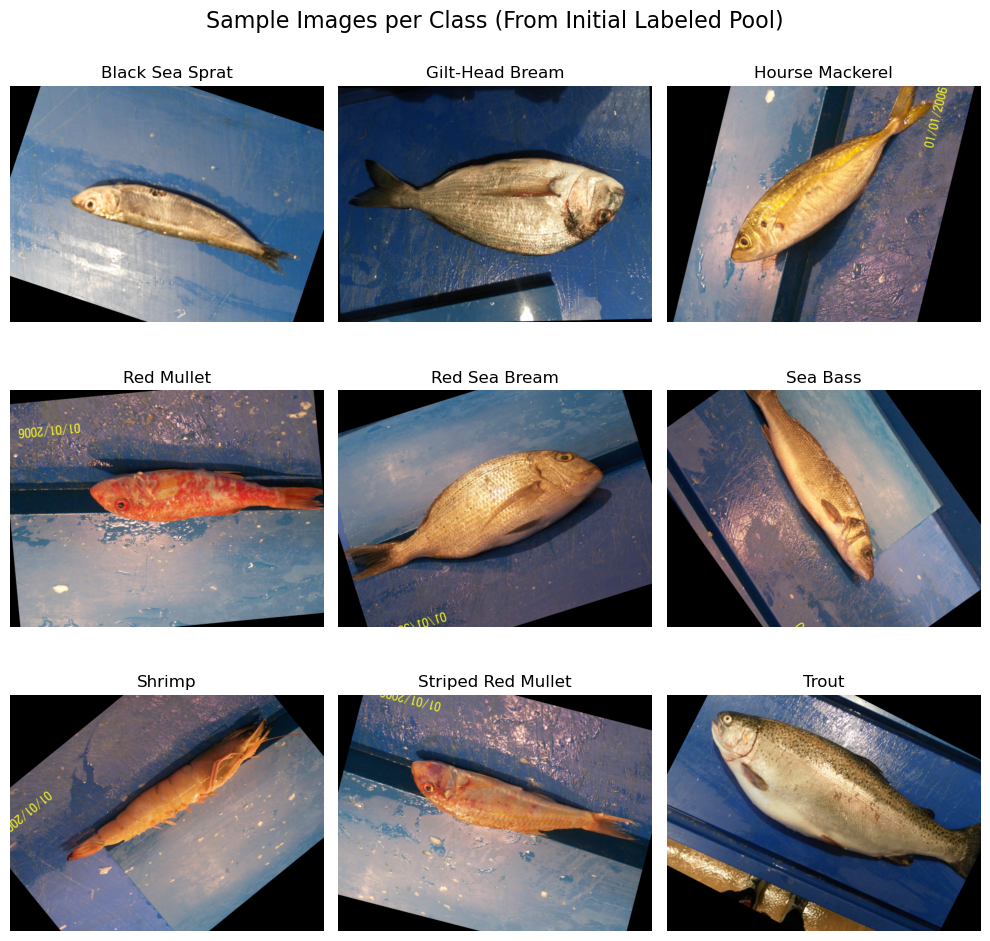

In [8]:
def plot_sample_images(target_dir='data/al_splits'):
    labeled_dir = Path(target_dir) / 'train_labeled'
        
    if not labeled_dir.exists():
        exit()
        
    classes = sorted([d.name for d in labeled_dir.iterdir() if d.is_dir()])

    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    fig.suptitle("Sample Images per Class (From Initial Labeled Pool)", fontsize=16)

    for i, class_name in enumerate(classes):
        if i >= 9: # Ensure we only plot 9 for a 3x3 grid
            break
            
        class_path = labeled_dir / class_name
        images = list(class_path.glob('*.png'))
        
        row, col = i // 3, i % 3
        ax = axes[row, col]
        
        if images:
            # Pick the first image as a sample
            img = mpimg.imread(str(images[0]))
            ax.imshow(img)
            
        ax.set_title(class_name)
        ax.axis('off')
        
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    plot_sample_images()

# Step 2: Baseline ResNet18 - Supervised Learning

## Configuration and Data Loading

In [9]:
base_dir='data/al_splits'
batch_size=32

# Standard ResNet transformations
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

eval_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Load datasets
train_labeled = datasets.ImageFolder(os.path.join(base_dir, 'train_labeled'), transform=train_transforms)
train_unlabeled = datasets.ImageFolder(os.path.join(base_dir, 'train_unlabeled'), transform=train_transforms)

# Combine labeled and unlabeled to form the FULL baseline training set
full_train_ds = ConcatDataset([train_labeled, train_unlabeled])

val_ds = datasets.ImageFolder(os.path.join(base_dir, 'val'), transform=eval_transforms)
test_ds = datasets.ImageFolder(os.path.join(base_dir, 'test'), transform=eval_transforms)

# Create DataLoaders
train_loader = DataLoader(full_train_ds, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2)

class_names = train_labeled.classes

## Model Setup

In [10]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

num_classes=9
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    
# Replace final FC layer
# The original ResNet-18 model is pre-trained on the ImageNet dataset, which has exactly 1000 classes.
# The fish dataset only has 9 classes, so we must replace the last layer. 
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, num_classes)

model = model.to(device)

Using device: cuda:0


## Training Loop with Early Stopping

In [11]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")

num_epochs=30
patience=5

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = StepLR(optimizer, step_size=7, gamma=0.1)

best_model_wts = copy.deepcopy(model.state_dict())
best_val_loss = float('inf')
epochs_no_improve = 0

for epoch in range(num_epochs):
    print(f"\nEpoch {epoch+1}/{num_epochs}")
    print("-" * 15)

    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    running_corrects = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        _, preds = torch.max(outputs, 1)
        
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels.data)
        total_train += inputs.size(0)

    scheduler.step()
    train_loss = running_loss / total_train
    train_acc = running_corrects.double() / total_train
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")

    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)

            val_loss += loss.item() * inputs.size(0)
            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())

    val_loss = val_loss / len(all_labels)
    val_acc = accuracy_score(all_labels, all_preds)
    precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)

    print(f"Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.4f}")
    print(f"Val Macro P: {precision:.4f} | Macro R: {recall:.4f} | Macro F1: {f1:.4f}")

    # --- EARLY STOPPING & SAVING ---
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_wts = copy.deepcopy(model.state_dict())
        epochs_no_improve = 0
        # Save the best model to disk
        torch.save(best_model_wts, 'models/resnet18_baseline_best.pth')
        print(">> Validation loss decreased. Saved best model weights.")
    else:
        epochs_no_improve += 1
        print(f">> No improvement for {epochs_no_improve} epoch(s).")
        if epochs_no_improve >= patience:
            print(">> Early stopping triggered!")
            break

print(f"\nTraining complete. Best Val Loss: {best_val_loss:.4f}")
# Load best model weights into the model before returning
model.load_state_dict(best_model_wts)

Using device: cuda:0

Epoch 1/30
---------------
Train Loss: 0.2455 | Train Acc: 0.9171
Val Loss:   0.1244 | Val Acc:   0.9611
Val Macro P: 0.9637 | Macro R: 0.9611 | Macro F1: 0.9611
>> Validation loss decreased. Saved best model weights.

Epoch 2/30
---------------
Train Loss: 0.0693 | Train Acc: 0.9762
Val Loss:   0.0488 | Val Acc:   0.9878
Val Macro P: 0.9886 | Macro R: 0.9878 | Macro F1: 0.9878
>> Validation loss decreased. Saved best model weights.

Epoch 3/30
---------------
Train Loss: 0.0438 | Train Acc: 0.9860
Val Loss:   0.0915 | Val Acc:   0.9589
Val Macro P: 0.9635 | Macro R: 0.9589 | Macro F1: 0.9592
>> No improvement for 1 epoch(s).

Epoch 4/30
---------------
Train Loss: 0.0436 | Train Acc: 0.9862
Val Loss:   0.0271 | Val Acc:   0.9933
Val Macro P: 0.9936 | Macro R: 0.9933 | Macro F1: 0.9934
>> Validation loss decreased. Saved best model weights.

Epoch 5/30
---------------
Train Loss: 0.0039 | Train Acc: 0.9992
Val Loss:   0.0001 | Val Acc:   1.0000
Val Macro P: 1.0000

<All keys matched successfully>

## Evaluation and Visualization


--- Evaluating on Test Set ---
Using device: cuda:0
Test Accuracy: 1.0000
Test Macro Precision: 1.0000
Test Macro Recall:    1.0000
Test Macro F1-Score:  1.0000

Per-Class Accuracy:
 - Black Sea Sprat     : 1.0000
 - Gilt-Head Bream     : 1.0000
 - Hourse Mackerel     : 1.0000
 - Red Mullet          : 1.0000
 - Red Sea Bream       : 1.0000
 - Sea Bass            : 1.0000
 - Shrimp              : 1.0000
 - Striped Red Mullet  : 1.0000
 - Trout               : 1.0000


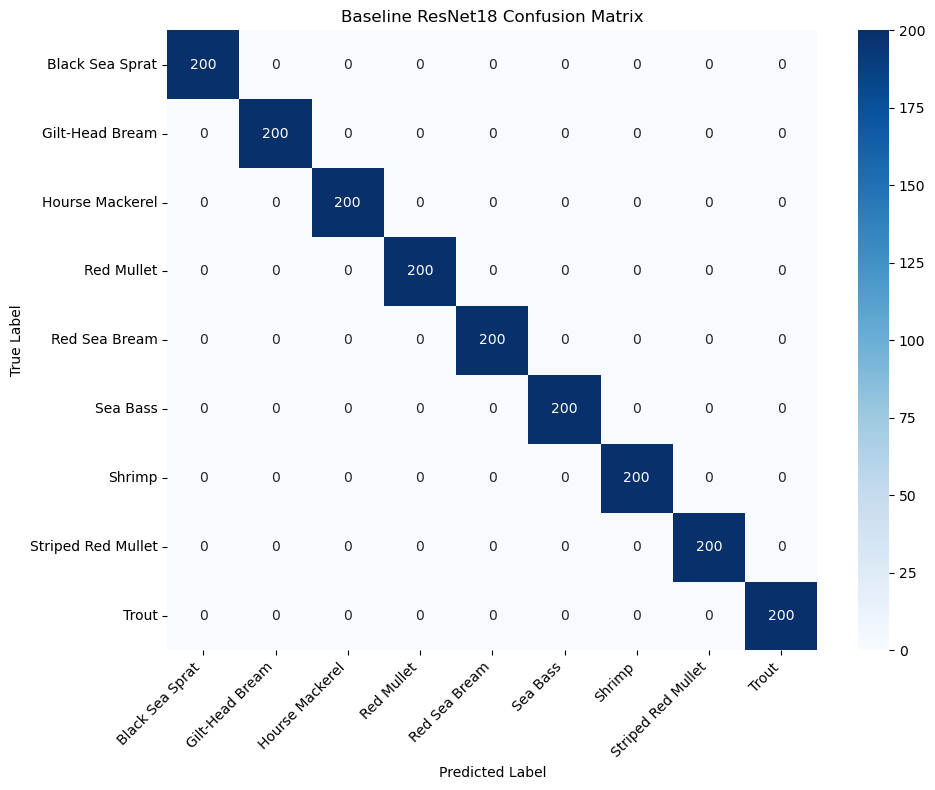

In [12]:
def initialize_model(num_classes=9):
    """Loads ResNet18 and modifies the final layer."""
    # Load pretrained weights
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    
    # Replace final FC layer
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)
    
    return model

print("\n--- Evaluating on Test Set ---")
device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")
model_path = 'models/resnet18_baseline_best.pth'
model = initialize_model(num_classes=9)
model.load_state_dict(torch.load(model_path, map_location=device))
model = model.to(device)
model.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        all_labels.extend(labels.numpy())
        all_preds.extend(preds.cpu().numpy())

# Calculate overall metrics
test_acc = accuracy_score(all_labels, all_preds)
precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)

print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Macro Precision: {precision:.4f}")
print(f"Test Macro Recall:    {recall:.4f}")
print(f"Test Macro F1-Score:  {f1:.4f}")

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

# Calculate Per-Class Accuracy from the confusion matrix
per_class_acc = cm.diagonal() / cm.sum(axis=1)
print("\nPer-Class Accuracy:")
for i, class_name in enumerate(class_names):
    print(f" - {class_name:<20}: {per_class_acc[i]:.4f}")

# Plotting Confusion Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Baseline ResNet18 Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('plots/baseline_confusion_matrix.png')
plt.show()

# Step 3: Feature Extraction and t-SNE - Unsupervised Learning

[*] Loading model from models/resnet18_baseline_best.pth...
[*] Extracting features from the test set...
[*] Running t-SNE on feature matrix of shape (1800, 512)...
    (This might take a minute or two depending on your CPU)
[*] t-SNE completed.
[*] Generating t-SNE plot...
[*] Plot saved to 'plots/tsne_baseline.png'


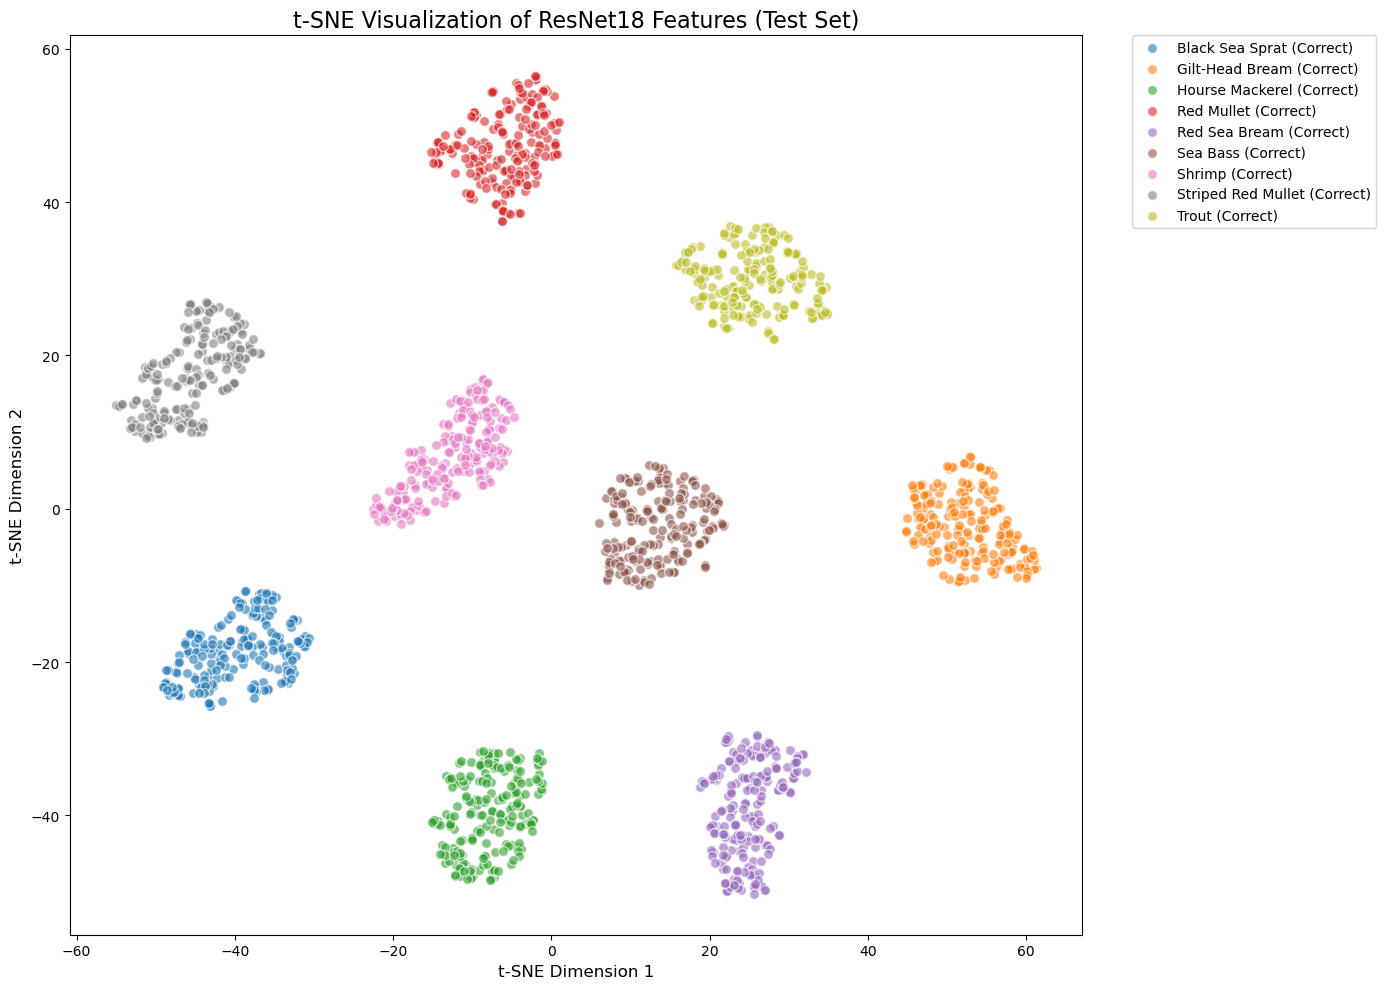

In [13]:
def get_dataloaders(base_dir='data/al_splits', batch_size=32):
    """Loads and transforms the datasets."""
    
    # Standard ResNet transformations
    train_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    
    eval_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    # Load datasets
    train_labeled = datasets.ImageFolder(os.path.join(base_dir, 'train_labeled'), transform=train_transforms)
    train_unlabeled = datasets.ImageFolder(os.path.join(base_dir, 'train_unlabeled'), transform=train_transforms)
    
    # Combine labeled and unlabeled to form the FULL baseline training set
    full_train_ds = ConcatDataset([train_labeled, train_unlabeled])
    
    val_ds = datasets.ImageFolder(os.path.join(base_dir, 'val'), transform=eval_transforms)
    test_ds = datasets.ImageFolder(os.path.join(base_dir, 'test'), transform=eval_transforms)

    # Create DataLoaders
    train_loader = DataLoader(full_train_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2)

    class_names = train_labeled.classes
    return train_loader, val_loader, test_loader, class_names

def initialize_model(num_classes=9):
    """Loads ResNet18 and modifies the final layer."""
    # Load pretrained weights
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    
    # Replace final FC layer
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, num_classes)
    
    return model

# ==========================================
# Feature Extraction Function
# ==========================================
def extract_features_and_predictions(model_path, test_loader, device, num_classes=9):
    """Loads the model, extracts embeddings, and records predictions."""
    print(f"[*] Loading model from {model_path}...")
    
    # Re-initialize the architecture and load best weights
    # (Assumes initialize_model is defined in your notebook from Step 2)
    model = initialize_model(num_classes=num_classes)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model = model.to(device)
    model.eval()

    # Save the final classification layer and replace it with Identity
    classifier = copy.deepcopy(model.fc)
    model.fc = nn.Identity()
    
    all_features = []
    all_labels = []
    all_preds = []

    print("[*] Extracting features from the test set...")
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs = inputs.to(device)
            
            # Get 512-D embeddings
            features = model(inputs)
            
            # Pass embeddings through the saved classifier to get predictions
            outputs = classifier(features)
            _, preds = torch.max(outputs, 1)
            
            # Store results
            all_features.append(features.cpu().numpy())
            all_labels.append(labels.numpy())
            all_preds.append(preds.cpu().numpy())

    # Concatenate lists into flat arrays
    all_features = np.concatenate(all_features, axis=0)
    all_labels = np.concatenate(all_labels, axis=0)
    all_preds = np.concatenate(all_preds, axis=0)

    return all_features, all_labels, all_preds

# ==========================================
# t-SNE Dimensionality Reduction
# ==========================================
def run_tsne(features):
    """Compresses 512-D features down to 2-D using t-SNE."""
    print(f"[*] Running t-SNE on feature matrix of shape {features.shape}...")
    print("    (This might take a minute or two depending on your CPU)")
    
    tsne = TSNE(n_components=2, random_state=seed, init='pca', learning_rate='auto')
    features_2d = tsne.fit_transform(features)
    
    print("[*] t-SNE completed.")
    return features_2d

# ==========================================
# Visualization
# ==========================================
def plot_tsne(features_2d, labels, preds, class_names):
    """Plots the 2D t-SNE embeddings and highlights misclassifications."""
    print("[*] Generating t-SNE plot...")
    
    plt.figure(figsize=(14, 10))
    
    # Create an array of booleans indicating if a point was misclassified
    misclassified = (labels != preds)
    
    # Define a color palette for our 9 classes
    palette = sns.color_palette("tab10", len(class_names))
    
    # Plot correctly classified points (lighter, standard markers)
    for i, class_name in enumerate(class_names):
        idx = (labels == i) & (~misclassified)
        plt.scatter(
            features_2d[idx, 0], features_2d[idx, 1], 
            label=f"{class_name} (Correct)", 
            color=palette[i], 
            alpha=0.6, 
            edgecolor='w', 
            s=50
        )
        
    # Plot misclassified points (larger, marked with an 'X' or dark border)
    for i, class_name in enumerate(class_names):
        idx = (labels == i) & misclassified
        if np.any(idx): # Only plot if there are actually mistakes for this class
            plt.scatter(
                features_2d[idx, 0], features_2d[idx, 1], 
                color=palette[i], 
                marker='X', # X marks the spot for errors
                edgecolor='black',
                linewidth=1,
                s=120, # Make them larger to stand out
                label=f"{class_name} (Error)"
            )

    plt.title("t-SNE Visualization of ResNet18 Features (Test Set)", fontsize=16)
    plt.xlabel("t-SNE Dimension 1", fontsize=12)
    plt.ylabel("t-SNE Dimension 2", fontsize=12)
    
    # Adjust legend to be outside the plot since there are many items
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10, borderaxespad=0.)
    plt.tight_layout()
    
    # Save the plot
    os.makedirs('plots', exist_ok=True)
    plot_path = 'plots/tsne_baseline.png'
    plt.savefig(plot_path, dpi=300)
    print(f"[*] Plot saved to '{plot_path}'")
    plt.show()

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    
    # Assuming get_dataloaders is already defined and data is prepped
    # We only need the test loader and class names for this step
    _, _, test_loader, class_names = get_dataloaders(batch_size=32)
    
    model_path = 'models/resnet18_baseline_best.pth'
    
    if not os.path.exists(model_path):
        print(f"[!] Warning: Could not find {model_path}. Did Step 2 complete successfully?")
    else:
        # Extract
        features, labels, preds = extract_features_and_predictions(model_path, test_loader, device)
        
        # Reduce Dimensions
        features_2d = run_tsne(features)
        
        # Plot
        plot_tsne(features_2d, labels, preds, class_names)

# Step 5: Active Learning Setup

In [14]:
# ==========================================
# AL Data Loading & Counting
# ==========================================
def get_al_dataloaders(base_dir='data/al_splits', batch_size=16):
    """Loads the initial labeled set, val, and test sets."""
    
    # Standard transforms
    train_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    
    eval_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    # Load datasets (NOTE: We only load train_labeled here, not train_unlabeled!!!)
    train_labeled_ds = datasets.ImageFolder(os.path.join(base_dir, 'train_labeled'), transform=train_transforms)
    val_ds = datasets.ImageFolder(os.path.join(base_dir, 'val'), transform=eval_transforms)
    test_ds = datasets.ImageFolder(os.path.join(base_dir, 'test'), transform=eval_transforms)

    # NOTE: Reduced batch size for Iteration 0 since dataset is very small
    train_loader = DataLoader(train_labeled_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2)

    num_labeled_samples = len(train_labeled_ds)
    class_names = train_labeled_ds.classes
    
    return train_loader, val_loader, test_loader, num_labeled_samples, class_names

# ==========================================
# Training Loop for AL Iteration
# ==========================================
def train_al_iteration(model, train_loader, val_loader, device, save_path, num_epochs=25, patience=5):
    """Trains the model and saves the best iteration based on val loss."""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    scheduler = StepLR(optimizer, step_size=7, gamma=0.1)

    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_loss = float('inf')
    epochs_no_improve = 0

    for epoch in range(num_epochs):
        model.train()
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
        scheduler.step()

        # Validation phase
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                
        val_loss = val_loss / len(val_loader.dataset)

        # Early stopping check
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
            torch.save(best_model_wts, save_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"    [Early stopping at epoch {epoch+1}]")
                break

    model.load_state_dict(best_model_wts)
    return model

# ==========================================
# Evaluation Function
# ==========================================
def evaluate_metrics(model, dataloader, device):
    """Calculates accuracy, precision, recall, and f1 for a given dataloader."""
    model.eval()
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_labels.extend(labels.numpy())
            all_preds.extend(preds.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    p, r, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    
    return acc, p, r, f1

# ==========================================
# Execution Block: Active Learning Iteration 0
# ==========================================
if __name__ == "__main__":
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    print(f"[*] Starting AL Iteration 0 on device: {device}")

    # Load Data
    train_loader, val_loader, test_loader, num_labeled, class_names = get_al_dataloaders(batch_size=16)
    print(f"[*] Initial Labeled Samples: {num_labeled}")

    # Initialize fresh model
    print("[*] Initializing fresh ResNet18 model...")
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    model = model.to(device)

    # Train Iteration 0
    save_path = 'models/resnet18_al_iter_0.pth'
    print("[*] Training model on initial labeled set...")
    model = train_al_iteration(model, train_loader, val_loader, device, save_path)
    model = model.to(device)

    # Evaluate and Record Metrics
    print("[*] Evaluating Iteration 0...")
    val_acc, val_p, val_r, val_f1 = evaluate_metrics(model, val_loader, device)
    test_acc, test_p, test_r, test_f1 = evaluate_metrics(model, test_loader, device)

    # Dictionary to store AL metrics across iterations
    al_metrics_history = []
    
    iter_0_results = {
        'iteration': 0,
        'labeled_samples': num_labeled,
        'val_accuracy': val_acc,
        'val_macro_p': val_p,
        'val_macro_r': val_r,
        'val_macro_f1': val_f1,
        'test_accuracy': test_acc,
        'test_macro_p': test_p,
        'test_macro_r': test_r,
        'test_macro_f1': test_f1
    }
    al_metrics_history.append(iter_0_results)

    print("\n--- Iteration 0 Results ---")
    print(f"Labeled Pool Size : {num_labeled}")
    print(f"Val Accuracy      : {val_acc:.4f} | Val F1 : {val_f1:.4f}")
    print(f"Test Accuracy     : {test_acc:.4f} | Test F1: {test_f1:.4f}")
    print(f"Model saved to    : {save_path}")

[*] Starting AL Iteration 0 on device: cuda:0
[*] Initial Labeled Samples: 90
[*] Initializing fresh ResNet18 model...
[*] Training model on initial labeled set...
[*] Evaluating Iteration 0...

--- Iteration 0 Results ---
Labeled Pool Size : 90
Val Accuracy      : 0.7944 | Val F1 : 0.7944
Test Accuracy     : 0.7667 | Test F1: 0.7659
Model saved to    : models/resnet18_al_iter_0.pth


# Step 6: Active Learning Loop

In [15]:
# ==========================================
# Custom Dataset to Retrieve File Paths
# ==========================================
class ImageFolderWithPaths(datasets.ImageFolder):
    """Custom dataset that includes image file paths. Extends torchvision.datasets.ImageFolder."""
    def __getitem__(self, index):
        # This returns the original tuple (image, label)
        original_tuple = super(ImageFolderWithPaths, self).__getitem__(index)
        # Get the path of the image
        path = self.imgs[index][0]
        # Return a new tuple that includes the path
        return original_tuple + (path,)

# ==========================================
# Uncertainty Sampling Functions
# ==========================================
def get_uncertainties(model, dataloader, device):
    """Calculates the Least Confidence uncertainty, optimized for speed."""
    print(f"[*] Calculating uncertainties using device: {device}")
    model.eval()
    
    # Store tensors instead of converting to numpy immediately
    all_uncertainties = []
    all_paths = []

    with torch.no_grad():
        for inputs, _, file_paths in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            
            probs = F.softmax(outputs, dim=1)
            max_probs, _ = torch.max(probs, dim=1)
            batch_uncertainties = 1.0 - max_probs
            
            # Keep the tensor, do not move to CPU yet
            all_uncertainties.append(batch_uncertainties)
            all_paths.extend(file_paths)

    # Concatenate all tensors at once, then move to CPU and convert to numpy
    # This heavily reduces CPU <-> GPU communication overhead
    final_uncertainties = torch.cat(all_uncertainties).cpu().numpy()
    
    return final_uncertainties, np.array(all_paths)

def query_and_move_samples(paths, uncertainties, top_k=10, dest_base='data/al_splits/train_labeled'):
    """Finds the top-k most uncertain samples and moves them to the labeled folder."""
    # Get the indices of the top-k highest uncertainties
    top_k_indices = np.argsort(uncertainties)[-top_k:]
    selected_paths = paths[top_k_indices]
    
    print(f"    [*] Querying oracle for {top_k} most uncertain images...")
    
    for file_path in selected_paths:
        # Extract class name and file name from the path
        path_parts = os.path.split(file_path)
        file_name = path_parts[1]
        class_name = os.path.split(path_parts[0])[1]
        
        # Define destination path and move the file
        dest_dir = os.path.join(dest_base, class_name)
        os.makedirs(dest_dir, exist_ok=True)
        shutil.move(file_path, os.path.join(dest_dir, file_name))
        
    return len(selected_paths)

# ==========================================
# Comprehensive Evaluation
# ==========================================
def evaluate_comprehensive(model, dataloader, class_names, device):
    """Evaluates and returns metrics, CM, and per-class accuracy."""
    model.eval()
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_labels.extend(labels.numpy())
            all_preds.extend(preds.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    p, r, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    
    cm = confusion_matrix(all_labels, all_preds)
    per_class_acc = cm.diagonal() / cm.sum(axis=1)
    
    # Store per-class accuracy in a dictionary mapping class name to score
    per_class_dict = {class_names[i]: per_class_acc[i] for i in range(len(class_names))}

    return acc, p, r, f1, cm, per_class_dict

# ==========================================
# Execution Block: Active Learning Loop
# ==========================================
if __name__ == "__main__":
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    
    # Transform for unlabeled data (no augmentation needed just for prediction)
    eval_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    # Assume model is currently loaded with the weights from Iteration 0
    # Make sure 'al_metrics_history' list exists from Step 5
    if 'al_metrics_history' not in locals():
        print("[!] al_metrics_history not found. Initializing new list.")
        al_metrics_history = []
        
    total_train_pool_size = 6300 # 700 images * 9 classes

    print("\nStarting Active Learning Loop...")
    
    for t in range(1, 6):
        print(f"\n==========================================")
        print(f"       ACTIVE LEARNING ITERATION {t}")
        print(f"==========================================")
        
        # Prepare Unlabeled DataLoader
        unlabeled_ds = ImageFolderWithPaths('data/al_splits/train_unlabeled', transform=eval_transforms)
        # Added pin_memory=True for faster CPU-to-GPU data transfer
        unlabeled_loader = DataLoader(
            unlabeled_ds, 
            batch_size=512, 
            shuffle=False, 
            num_workers=0, 
            pin_memory=True
        )
        
        # Compute Uncertainty & Query
        print(f"[*] Scanning {len(unlabeled_ds)} unlabeled samples...")
        uncertainties, paths = get_uncertainties(model, unlabeled_loader, device)
        query_and_move_samples(paths, uncertainties, top_k=10)
        
        # Rebuild Standard DataLoaders with updated labeled set
        print("[*] Rebuilding dataloaders...")
        train_loader, val_loader, test_loader, num_labeled, class_names = get_al_dataloaders(batch_size=16)
        
        budget_percent = (num_labeled / total_train_pool_size) * 100
        print(f"[*] Current Labeled Pool: {num_labeled} images (Budget: {budget_percent:.2f}%)")
        
        # Train Model (Warm start - using weights from iteration t-1)
        save_path = f'models/resnet18_al_iter_{t}.pth'
        print("[*] Retraining model...")
        # Re-using the training function from Step 5
        model = train_al_iteration(model, train_loader, val_loader, device, save_path, num_epochs=20, patience=5)
        
        # Evaluate and Record
        print("[*] Evaluating...")
        val_acc, val_p, val_r, val_f1, _, _ = evaluate_comprehensive(model, val_loader, class_names, device)
        test_acc, test_p, test_r, test_f1, test_cm, test_per_class = evaluate_comprehensive(model, test_loader, class_names, device)
        
        # Save Metrics
        iter_results = {
            'iteration': t,
            'labeled_samples': num_labeled,
            'budget_percent': budget_percent,
            'val_accuracy': val_acc,
            'val_macro_p': val_p,
            'val_macro_r': val_r,
            'val_macro_f1': val_f1,
            'test_accuracy': test_acc,
            'test_macro_p': test_p,
            'test_macro_r': test_r,
            'test_macro_f1': test_f1,
            'test_per_class_acc': test_per_class,
            'test_confusion_matrix': test_cm.tolist() # Convert numpy array to list for easier saving later
        }
        al_metrics_history.append(iter_results)
        
        print(f"    -> Val F1: {val_f1:.4f} | Test F1: {test_f1:.4f}")

        # ==========================================
        # MEMORY CLEANUP BLOCK
        # ==========================================
        # 1. Delete temporary variables that hold large tensors/datasets
        del train_loader, val_loader, test_loader, unlabeled_loader, unlabeled_ds
        del uncertainties, paths, val_acc, test_acc # Delete metrics variables too
        
        # 2. Force Python's Garbage Collector to run
        gc.collect()
        
        # 3. Empty PyTorch's CUDA cache
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print("\n[*] Active Learning Loop Complete!")


Starting Active Learning Loop...

       ACTIVE LEARNING ITERATION 1
[*] Scanning 6210 unlabeled samples...
[*] Calculating uncertainties using device: cuda:0
    [*] Querying oracle for 10 most uncertain images...
[*] Rebuilding dataloaders...
[*] Current Labeled Pool: 100 images (Budget: 1.59%)
[*] Retraining model...
[*] Evaluating...
    -> Val F1: 0.7538 | Test F1: 0.7440

       ACTIVE LEARNING ITERATION 2
[*] Scanning 6200 unlabeled samples...
[*] Calculating uncertainties using device: cuda:0
    [*] Querying oracle for 10 most uncertain images...
[*] Rebuilding dataloaders...
[*] Current Labeled Pool: 110 images (Budget: 1.75%)
[*] Retraining model...
[*] Evaluating...
    -> Val F1: 0.7562 | Test F1: 0.7452

       ACTIVE LEARNING ITERATION 3
[*] Scanning 6190 unlabeled samples...
[*] Calculating uncertainties using device: cuda:0
    [*] Querying oracle for 10 most uncertain images...
[*] Rebuilding dataloaders...
[*] Current Labeled Pool: 120 images (Budget: 1.90%)
[*] Ret

# Step 7: Random Sampling

In [ ]:
# import os
# import random
# import shutil
# import torch
# import torch.nn as nn
# from torchvision import datasets, transforms, models
# from torch.utils.data import DataLoader
# import gc

# ==========================================
# 1. Random Sampling Helper
# ==========================================
def query_random_samples(unlabeled_ds, top_k=10, dest_base='data/al_splits/train_labeled'):
    """Randomly selects top_k samples from the unlabeled dataset and moves them."""
    
    # unlabeled_ds.imgs contains tuples of (file_path, class_index)
    # We extract just the file paths
    all_paths = [item[0] for item in unlabeled_ds.imgs]
    
    # Randomly select K paths
    selected_paths = random.sample(all_paths, top_k)
    
    print(f"    [*] Randomly querying oracle for {top_k} images...")
    
    for file_path in selected_paths:
        path_parts = os.path.split(file_path)
        file_name = path_parts[1]
        class_name = os.path.split(path_parts[0])[1]
        
        dest_dir = os.path.join(dest_base, class_name)
        os.makedirs(dest_dir, exist_ok=True)
        shutil.move(file_path, os.path.join(dest_dir, file_name))
        
    return len(selected_paths)

# ==========================================
# Execution Block: Random Baseline Loop
# ==========================================
if __name__ == "__main__":
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    print(f"[*] Starting Random Baseline on device: {device}")

    # 1. RESET THE DATASET
    print("\n[*] Resetting dataset to Initial State (Iteration 0)...")
    print("[*] Wiping old splits and creating fresh imbalanced directories...")
    if os.path.exists('data/al_splits'):
        shutil.rmtree('data/al_splits')# This will wipe the AL folders
    create_al_splits()  # This will recreate the perfect split
    
    random_metrics_history = []
    total_train_pool_size = 6300

    # 2. TRAIN RANDOM ITERATION 0
    print("\n[*] Training Random Iteration 0 (Fresh Start)...")
    train_loader, val_loader, test_loader, num_labeled, class_names = get_al_dataloaders(batch_size=16)
    
    # Fresh Model
    random_model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    random_model.fc = nn.Linear(random_model.fc.in_features, len(class_names))
    random_model = random_model.to(device)
    
    save_path_0 = 'models/resnet18_random_iter_0.pth'
    random_model = train_al_iteration(random_model, train_loader, val_loader, device, save_path_0, num_epochs=25, patience=5)
    
    val_acc, val_p, val_r, val_f1, _, _ = evaluate_comprehensive(random_model, val_loader, class_names, device)
    test_acc, test_p, test_r, test_f1, test_cm, test_per_class = evaluate_comprehensive(random_model, test_loader, class_names, device)
    
    budget_percent = (num_labeled / total_train_pool_size) * 100
    random_metrics_history.append({
        'iteration': 0, 'labeled_samples': num_labeled, 'budget_percent': budget_percent,
        'val_accuracy': val_acc, 'val_macro_f1': val_f1,
        'test_accuracy': test_acc, 'test_macro_f1': test_f1,
        'test_per_class_acc': test_per_class, 'test_confusion_matrix': test_cm.tolist()
    })
    print(f"    -> Iteration 0 | Labeled: {num_labeled} | Test F1: {test_f1:.4f}")

    # 3. RANDOM SAMPLING LOOP (T = 1..5)
    print("\nStarting Random Sampling Loop...")
    
    for t in range(1, 6):
        print(f"\n==========================================")
        print(f"       RANDOM ITERATION {t}")
        print(f"==========================================")
        
        # We don't need ImageFolderWithPaths since we don't pass data through the model
        # Standard ImageFolder is enough to get the paths via .imgs
        unlabeled_ds = datasets.ImageFolder('data/al_splits/train_unlabeled')
        
        # Query random samples
        query_random_samples(unlabeled_ds, top_k=10)
        
        # Rebuild dataloaders
        print("[*] Rebuilding dataloaders...")
        train_loader, val_loader, test_loader, num_labeled, class_names = get_al_dataloaders(batch_size=16)
        
        budget_percent = (num_labeled / total_train_pool_size) * 100
        print(f"[*] Current Labeled Pool: {num_labeled} images (Budget: {budget_percent:.2f}%)")
        
        # Retrain
        save_path = f'models/resnet18_random_iter_{t}.pth'
        print("[*] Retraining model...")
        random_model = train_al_iteration(random_model, train_loader, val_loader, device, save_path, num_epochs=20, patience=5)
        
        # Evaluate
        print("[*] Evaluating...")
        val_acc, val_p, val_r, val_f1, _, _ = evaluate_comprehensive(random_model, val_loader, class_names, device)
        test_acc, test_p, test_r, test_f1, test_cm, test_per_class = evaluate_comprehensive(random_model, test_loader, class_names, device)
        
        random_metrics_history.append({
            'iteration': t, 'labeled_samples': num_labeled, 'budget_percent': budget_percent,
            'val_accuracy': val_acc, 'val_macro_f1': val_f1,
            'test_accuracy': test_acc, 'test_macro_f1': test_f1,
            'test_per_class_acc': test_per_class, 'test_confusion_matrix': test_cm.tolist()
        })
        print(f"    -> Val F1: {val_f1:.4f} | Test F1: {test_f1:.4f}")

        # Memory Cleanup Block (Always good to have!)
        del train_loader, val_loader, test_loader, unlabeled_ds
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print("\n[*] Random Baseline Loop Complete!")

[*] Starting Random Baseline on device: cuda:0

[*] Resetting dataset to Initial State (Iteration 0)...
[*] Creating split directories...
[*] Partitioning data...
[*] Data successfully partitioned into 'data/al_splits'

[*] Training Random Iteration 0 (Fresh Start)...
    -> Iteration 0 | Labeled: 90 | Test F1: 0.7902

Starting Random Sampling Loop...

       RANDOM ITERATION 1
    [*] Randomly querying oracle for 10 images...
[*] Rebuilding dataloaders...
[*] Current Labeled Pool: 100 images (Budget: 1.59%)
[*] Retraining model...
    [Early stopping at epoch 19]
[*] Evaluating...
    -> Val F1: 0.7307 | Test F1: 0.7601

       RANDOM ITERATION 2
    [*] Randomly querying oracle for 10 images...
[*] Rebuilding dataloaders...
[*] Current Labeled Pool: 110 images (Budget: 1.75%)
[*] Retraining model...
    [Early stopping at epoch 20]
[*] Evaluating...
    -> Val F1: 0.7514 | Test F1: 0.7686

       RANDOM ITERATION 3
    [*] Randomly querying oracle for 10 images...
[*] Rebuilding data

# Visualizing Metrics for a Balanced Dataset

[*] Generating visual reports...
[*] Learning curves saved to 'plots\learning_curves_comparison.png'


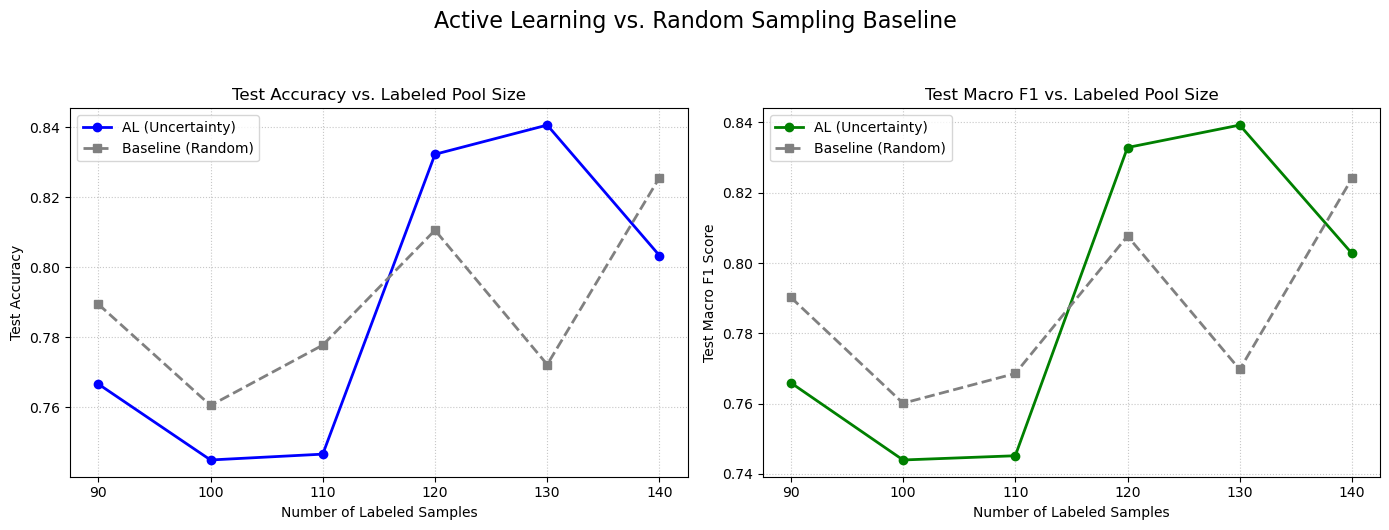


 PAPER REPORT: TEST SET PERFORMANCE COMPARISON
 Iteration  Labeled Samples Data Budget (%) Random Acc AL Acc Random F1  AL F1
         0               90           1.43%     0.7894 0.7667    0.7902 0.7659
         1              100           1.59%     0.7606 0.7450    0.7601 0.7440
         2              110           1.75%     0.7778 0.7467    0.7686 0.7452
         3              120           1.90%     0.8106 0.8322    0.8077 0.8329
         4              130           2.06%     0.7722 0.8406    0.7697 0.8393
         5              140           2.22%     0.8256 0.8033    0.8241 0.8027

[*] Metrics table saved to 'plots/metrics_comparison_table.csv'


In [17]:
# ==========================================
# 1. Plot Learning Curves
# ==========================================
def plot_learning_curves(al_history, random_history, save_dir='plots'):
    """Generates and saves learning curves comparing AL and Random sampling."""
    os.makedirs(save_dir, exist_ok=True)
    
    # Extract data for plotting
    al_samples = [x['labeled_samples'] for x in al_history]
    al_acc = [x['test_accuracy'] for x in al_history]
    al_f1 = [x['test_macro_f1'] for x in al_history]
    
    rand_samples = [x['labeled_samples'] for x in random_history]
    rand_acc = [x['test_accuracy'] for x in random_history]
    rand_f1 = [x['test_macro_f1'] for x in random_history]

    # Create a 1x2 subplot figure
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Active Learning vs. Random Sampling Baseline', fontsize=16, y=1.05)

    # Plot 1: Test Accuracy
    axes[0].plot(al_samples, al_acc, marker='o', linewidth=2, label='AL (Uncertainty)', color='blue')
    axes[0].plot(rand_samples, rand_acc, marker='s', linewidth=2, linestyle='--', label='Baseline (Random)', color='gray')
    axes[0].set_title('Test Accuracy vs. Labeled Pool Size')
    axes[0].set_xlabel('Number of Labeled Samples')
    axes[0].set_ylabel('Test Accuracy')
    axes[0].grid(True, linestyle=':', alpha=0.7)
    axes[0].legend()

    # Plot 2: Test Macro F1
    axes[1].plot(al_samples, al_f1, marker='o', linewidth=2, label='AL (Uncertainty)', color='green')
    axes[1].plot(rand_samples, rand_f1, marker='s', linewidth=2, linestyle='--', label='Baseline (Random)', color='gray')
    axes[1].set_title('Test Macro F1 vs. Labeled Pool Size')
    axes[1].set_xlabel('Number of Labeled Samples')
    axes[1].set_ylabel('Test Macro F1 Score')
    axes[1].grid(True, linestyle=':', alpha=0.7)
    axes[1].legend()

    plt.tight_layout()
    save_path = os.path.join(save_dir, 'learning_curves_comparison.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"[*] Learning curves saved to '{save_path}'")
    plt.show()

# ==========================================
# 2. Generate Paper-Ready Tables (FIXED)
# ==========================================
def generate_metrics_table(al_history, random_history, total_train_pool=6300):
    """Combines metrics into a Pandas DataFrame for easy viewing and reporting."""
    table_data = []
    
    for i in range(len(al_history)):
        al_iter = al_history[i]
        rand_iter = random_history[i]
        
        # FIX: Calculate budget dynamically so we don't rely on the missing key in Iteration 0
        budget_pct = (al_iter['labeled_samples'] / total_train_pool) * 100
        
        row = {
            'Iteration': al_iter['iteration'],
            'Labeled Samples': al_iter['labeled_samples'],
            'Data Budget (%)': f"{budget_pct:.2f}%",
            'Random Acc': f"{rand_iter['test_accuracy']:.4f}",
            'AL Acc': f"{al_iter['test_accuracy']:.4f}",
            'Random F1': f"{rand_iter['test_macro_f1']:.4f}",
            'AL F1': f"{al_iter['test_macro_f1']:.4f}"
        }
        table_data.append(row)
        
    df = pd.DataFrame(table_data)
    
    print("\n" + "="*70)
    print(" PAPER REPORT: TEST SET PERFORMANCE COMPARISON")
    print("="*70)
    try:
        print(df.to_markdown(index=False))
    except ImportError:
        print(df.to_string(index=False))
    print("="*70 + "\n")
    
    return df

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    if 'al_metrics_history' not in locals() or 'random_metrics_history' not in locals():
        print("[!] Error: History lists not found in memory.")
    else:
        print("[*] Generating visual reports...")
        plot_learning_curves(al_metrics_history, random_metrics_history)
        
        comparison_df = generate_metrics_table(al_metrics_history, random_metrics_history)
        comparison_df.to_csv('plots/metrics_comparison_table.csv', index=False)
        print("[*] Metrics table saved to 'plots/metrics_comparison_table.csv'")

# What if dataset is imbalanced?

## Introducing Class Imbalance

[*] Wiping old splits and creating fresh imbalanced directories...
[*] Imbalanced data successfully partitioned into 'data/al_splits'


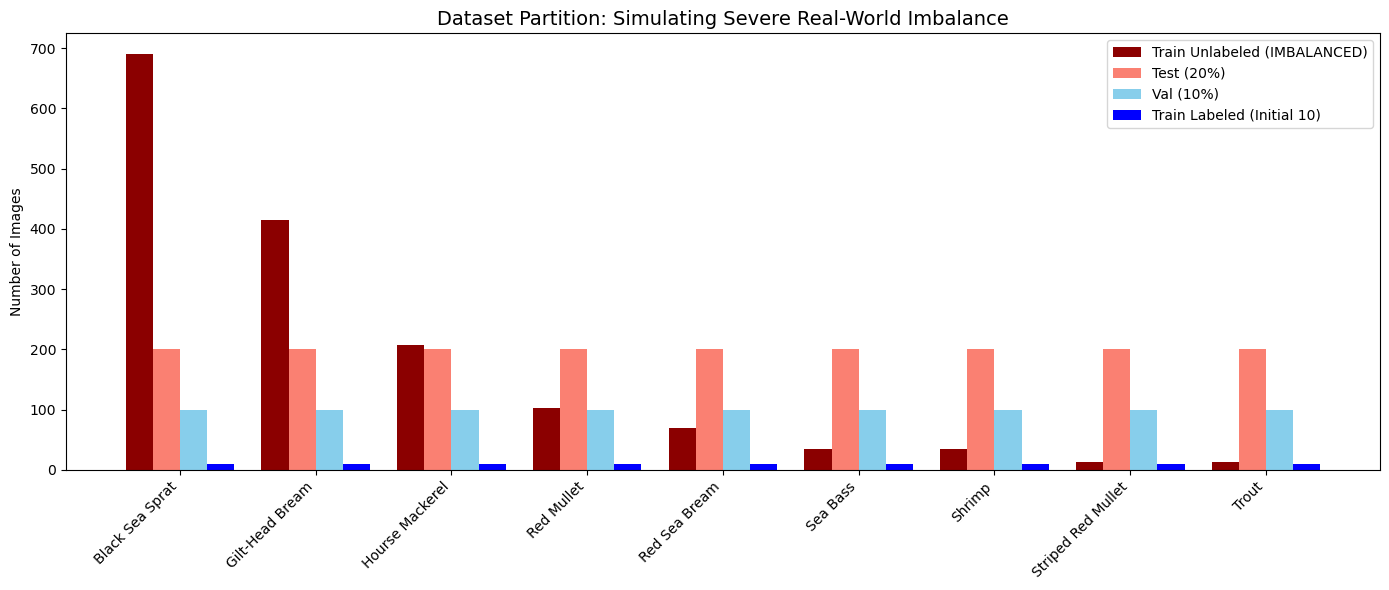

In [18]:
# import os
# import random
# import shutil
# import matplotlib.pyplot as plt
# import numpy as np
# from pathlib import Path

# ==========================================
# 1. Imbalanced Train / Val / Test Split
# ==========================================
def create_imbalanced_al_splits(source_dir='data/fish_dataset', target_dir='data/al_splits'):
    """Partitions the dataset, forcing severe imbalance in the unlabeled pool."""
    
    source_path = Path(source_dir)
    if not source_path.exists():
        print(f"[!] Error: Source directory '{source_dir}' not found.")
        return

    splits = ['test', 'val', 'train_labeled', 'train_unlabeled']
    
    print("[*] Wiping old splits and creating fresh imbalanced directories...")
    if os.path.exists(target_dir):
        shutil.rmtree(target_dir)
        
    for split in splits:
        os.makedirs(Path(target_dir) / split, exist_ok=True)

    random.seed(seed)
    classes = sorted([d.name for d in source_path.iterdir() if d.is_dir()])
    
    # Define a severe imbalance curve (1.0 = 100% of remaining data, 0.02 = 2%)
    imbalance_ratios = [1.0, 0.6, 0.3, 0.15, 0.1, 0.05, 0.05, 0.02, 0.02]

    for i, class_name in enumerate(classes):
        for split in splits:
            os.makedirs(Path(target_dir) / split / class_name, exist_ok=True)

        class_path = source_path / class_name
        images = sorted(list(class_path.glob('*.png')))
        random.shuffle(images)

        # Keep Test (200), Val (100), and Initial Labeled (10) perfectly balanced!
        test_imgs = images[:200]
        val_imgs = images[200:300]
        train_labeled_imgs = images[300:310]
        
        # Severely throttle the unlabeled pool based on the class index
        remaining_unlabeled = images[310:]
        allowed_count = int(len(remaining_unlabeled) * imbalance_ratios[i])
        train_unlabeled_imgs = remaining_unlabeled[:allowed_count]

        def copy_files(file_list, dest_split):
            dest_dir = Path(target_dir) / dest_split / class_name
            for img_path in file_list:
                shutil.copy(str(img_path), str(dest_dir / img_path.name))

        copy_files(test_imgs, 'test')
        copy_files(val_imgs, 'val')
        copy_files(train_labeled_imgs, 'train_labeled')
        copy_files(train_unlabeled_imgs, 'train_unlabeled')

    print(f"[*] Imbalanced data successfully partitioned into '{target_dir}'")

# ==========================================
# 2. Visualize the Imbalance
# ==========================================
def plot_imbalanced_distribution(target_dir='data/al_splits'):
    """Plots a stacked bar chart to verify the severe imbalance."""
    target_path = Path(target_dir)
    splits = ['train_labeled', 'train_unlabeled', 'val', 'test']
    classes = sorted([d.name for d in (target_path / 'test').iterdir() if d.is_dir()])
    
    counts = {split: [] for split in splits}
    for split in splits:
        for class_name in classes:
            split_class_dir = target_path / split / class_name
            counts[split].append(len(list(split_class_dir.glob('*.png'))))

    x = np.arange(len(classes))
    width = 0.2

    fig, ax = plt.subplots(figsize=(14, 6))
    
    # We plot the unlabeled pool first to highlight the cliff
    ax.bar(x - 1.5*width, counts['train_unlabeled'], width, label='Train Unlabeled (IMBALANCED)', color='darkred')
    ax.bar(x - 0.5*width, counts['test'], width, label='Test (20%)', color='salmon')
    ax.bar(x + 0.5*width, counts['val'], width, label='Val (10%)', color='skyblue')
    ax.bar(x + 1.5*width, counts['train_labeled'], width, label='Train Labeled (Initial 10)', color='blue')

    ax.set_ylabel('Number of Images')
    ax.set_title('Dataset Partition: Simulating Severe Real-World Imbalance', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(classes, rotation=45, ha='right')
    ax.legend()
    plt.tight_layout()
    plt.show()

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    create_imbalanced_al_splits()
    plot_imbalanced_distribution()

## Step 5: Active Learning Setup

In [19]:
# ==========================================
# AL Data Loading & Counting
# ==========================================
def get_al_dataloaders(base_dir='data/al_splits', batch_size=16):
    """Loads the initial labeled set, val, and test sets."""
    
    # Standard transforms
    train_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])
    
    eval_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    # Load datasets (NOTE: We only load train_labeled here, not train_unlabeled!!!)
    train_labeled_ds = datasets.ImageFolder(os.path.join(base_dir, 'train_labeled'), transform=train_transforms)
    val_ds = datasets.ImageFolder(os.path.join(base_dir, 'val'), transform=eval_transforms)
    test_ds = datasets.ImageFolder(os.path.join(base_dir, 'test'), transform=eval_transforms)

    # NOTE: Reduced batch size for Iteration 0 since dataset is very small
    train_loader = DataLoader(train_labeled_ds, batch_size=batch_size, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, num_workers=2)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2)

    num_labeled_samples = len(train_labeled_ds)
    class_names = train_labeled_ds.classes
    
    return train_loader, val_loader, test_loader, num_labeled_samples, class_names

# ==========================================
# Training Loop for AL Iteration
# ==========================================
def train_al_iteration(model, train_loader, val_loader, device, save_path, num_epochs=25, patience=5):
    """Trains the model and saves the best iteration based on val loss."""
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    scheduler = StepLR(optimizer, step_size=7, gamma=0.1)

    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_loss = float('inf')
    epochs_no_improve = 0

    for epoch in range(num_epochs):
        model.train()
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
        scheduler.step()

        # Validation phase
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                
        val_loss = val_loss / len(val_loader.dataset)

        # Early stopping check
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_wts = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
            torch.save(best_model_wts, save_path)
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"    [Early stopping at epoch {epoch+1}]")
                break

    model.load_state_dict(best_model_wts)
    return model

# ==========================================
# Evaluation Function
# ==========================================
def evaluate_metrics(model, dataloader, device):
    """Calculates accuracy, precision, recall, and f1 for a given dataloader."""
    model.eval()
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_labels.extend(labels.numpy())
            all_preds.extend(preds.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    p, r, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    
    return acc, p, r, f1

# ==========================================
# Execution Block: Active Learning Iteration 0
# ==========================================
if __name__ == "__main__":
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    print(f"[*] Starting AL Iteration 0 on device: {device}")

    # Load Data
    train_loader, val_loader, test_loader, num_labeled, class_names = get_al_dataloaders(batch_size=16)
    print(f"[*] Initial Labeled Samples: {num_labeled}")

    # Initialize fresh model
    print("[*] Initializing fresh ResNet18 model...")
    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    model = model.to(device)

    # Train Iteration 0
    save_path = 'models/resnet18_al_iter_0.pth'
    print("[*] Training model on initial labeled set...")
    model = train_al_iteration(model, train_loader, val_loader, device, save_path)
    model = model.to(device)

    # Evaluate and Record Metrics
    print("[*] Evaluating Iteration 0...")
    val_acc, val_p, val_r, val_f1 = evaluate_metrics(model, val_loader, device)
    test_acc, test_p, test_r, test_f1 = evaluate_metrics(model, test_loader, device)

    # Dictionary to store AL metrics across iterations
    al_metrics_history = []
    
    iter_0_results = {
        'iteration': 0,
        'labeled_samples': num_labeled,
        'val_accuracy': val_acc,
        'val_macro_p': val_p,
        'val_macro_r': val_r,
        'val_macro_f1': val_f1,
        'test_accuracy': test_acc,
        'test_macro_p': test_p,
        'test_macro_r': test_r,
        'test_macro_f1': test_f1
    }
    al_metrics_history.append(iter_0_results)

    print("\n--- Iteration 0 Results ---")
    print(f"Labeled Pool Size : {num_labeled}")
    print(f"Val Accuracy      : {val_acc:.4f} | Val F1 : {val_f1:.4f}")
    print(f"Test Accuracy     : {test_acc:.4f} | Test F1: {test_f1:.4f}")
    print(f"Model saved to    : {save_path}")

[*] Starting AL Iteration 0 on device: cuda:0
[*] Initial Labeled Samples: 90
[*] Initializing fresh ResNet18 model...
[*] Training model on initial labeled set...
    [Early stopping at epoch 19]
[*] Evaluating Iteration 0...

--- Iteration 0 Results ---
Labeled Pool Size : 90
Val Accuracy      : 0.7711 | Val F1 : 0.7645
Test Accuracy     : 0.7661 | Test F1: 0.7590
Model saved to    : models/resnet18_al_iter_0.pth


## Step 6: Active Learning Loop

In [ ]:
# ==========================================
# Custom Dataset to Retrieve File Paths
# ==========================================
class ImageFolderWithPaths(datasets.ImageFolder):
    """Custom dataset that includes image file paths. Extends torchvision.datasets.ImageFolder."""
    def __getitem__(self, index):
        # This returns the original tuple (image, label)
        original_tuple = super(ImageFolderWithPaths, self).__getitem__(index)
        # Get the path of the image
        path = self.imgs[index][0]
        # Return a new tuple that includes the path
        return original_tuple + (path,)

# ==========================================
# Uncertainty Sampling Functions
# ==========================================
def get_uncertainties(model, dataloader, device):
    """Calculates the Least Confidence uncertainty, optimized for speed."""
    print(f"[*] Calculating uncertainties using device: {device}")
    model.eval()
    
    # Store tensors instead of converting to numpy immediately
    all_uncertainties = []
    all_paths = []

    with torch.no_grad():
        for inputs, _, file_paths in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            
            probs = F.softmax(outputs, dim=1)
            max_probs, _ = torch.max(probs, dim=1)
            batch_uncertainties = 1.0 - max_probs
            
            # Keep the tensor, do not move to CPU yet
            all_uncertainties.append(batch_uncertainties)
            all_paths.extend(file_paths)

    # Concatenate all tensors at once, then move to CPU and convert to numpy
    # This heavily reduces CPU <-> GPU communication overhead
    final_uncertainties = torch.cat(all_uncertainties).cpu().numpy()
    
    return final_uncertainties, np.array(all_paths)

def query_and_move_samples(paths, uncertainties, top_k=10, dest_base='data/al_splits/train_labeled'):
    """Finds the top-k most uncertain samples and moves them to the labeled folder."""
    # Get the indices of the top-k highest uncertainties
    top_k_indices = np.argsort(uncertainties)[-top_k:]
    selected_paths = paths[top_k_indices]
    
    print(f"    [*] Querying oracle for {top_k} most uncertain images...")
    
    for file_path in selected_paths:
        # Extract class name and file name from the path
        path_parts = os.path.split(file_path)
        file_name = path_parts[1]
        class_name = os.path.split(path_parts[0])[1]
        
        # Define destination path and move the file
        dest_dir = os.path.join(dest_base, class_name)
        os.makedirs(dest_dir, exist_ok=True)
        shutil.move(file_path, os.path.join(dest_dir, file_name))
        
    return len(selected_paths)

# ==========================================
# Comprehensive Evaluation
# ==========================================
def evaluate_comprehensive(model, dataloader, class_names, device):
    """Evaluates and returns metrics, CM, and per-class accuracy."""
    model.eval()
    all_labels = []
    all_preds = []

    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            all_labels.extend(labels.numpy())
            all_preds.extend(preds.cpu().numpy())

    acc = accuracy_score(all_labels, all_preds)
    p, r, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='macro', zero_division=0)
    
    cm = confusion_matrix(all_labels, all_preds)
    per_class_acc = cm.diagonal() / cm.sum(axis=1)
    
    # Store per-class accuracy in a dictionary mapping class name to score
    per_class_dict = {class_names[i]: per_class_acc[i] for i in range(len(class_names))}

    return acc, p, r, f1, cm, per_class_dict

# ==========================================
# Execution Block: Active Learning Loop
# ==========================================
if __name__ == "__main__":
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    
    # Transform for unlabeled data (no augmentation needed just for prediction)
    eval_transforms = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    # Assume model is currently loaded with the weights from Iteration 0
    # Make sure 'al_metrics_history' list exists from Step 5
    if 'al_metrics_history' not in locals():
        print("[!] al_metrics_history not found. Initializing new list.")
        al_metrics_history = []
        
    total_train_pool_size = 6300 # 700 images * 9 classes

    print("\nStarting Active Learning Loop...")
    
    for t in range(1, 6):
        print(f"\n==========================================")
        print(f"       ACTIVE LEARNING ITERATION {t}")
        print(f"==========================================")
        
        # Prepare Unlabeled DataLoader
        unlabeled_ds = ImageFolderWithPaths('data/al_splits/train_unlabeled', transform=eval_transforms)
        # Added pin_memory=True for faster CPU-to-GPU data transfer
        unlabeled_loader = DataLoader(
            unlabeled_ds, 
            batch_size=512, 
            shuffle=False, 
            num_workers=0, 
            pin_memory=True
        )
        
        # Compute Uncertainty & Query
        print(f"[*] Scanning {len(unlabeled_ds)} unlabeled samples...")
        uncertainties, paths = get_uncertainties(model, unlabeled_loader, device)
        query_and_move_samples(paths, uncertainties, top_k=10)
        
        # Rebuild Standard DataLoaders with updated labeled set
        print("[*] Rebuilding dataloaders...")
        train_loader, val_loader, test_loader, num_labeled, class_names = get_al_dataloaders(batch_size=16)
        
        budget_percent = (num_labeled / total_train_pool_size) * 100
        print(f"[*] Current Labeled Pool: {num_labeled} images (Budget: {budget_percent:.2f}%)")
        
        # Train Model (Warm start - using weights from iteration t-1)
        save_path = f'models/resnet18_al_iter_{t}.pth'
        print("[*] Retraining model...")
        # Re-using the training function from Step 5
        model = train_al_iteration(model, train_loader, val_loader, device, save_path, num_epochs=20, patience=5)
        
        # Evaluate and Record
        print("[*] Evaluating...")
        val_acc, val_p, val_r, val_f1, _, _ = evaluate_comprehensive(model, val_loader, class_names, device)
        test_acc, test_p, test_r, test_f1, test_cm, test_per_class = evaluate_comprehensive(model, test_loader, class_names, device)
        
        # Save Metrics
        iter_results = {
            'iteration': t,
            'labeled_samples': num_labeled,
            'budget_percent': budget_percent,
            'val_accuracy': val_acc,
            'val_macro_p': val_p,
            'val_macro_r': val_r,
            'val_macro_f1': val_f1,
            'test_accuracy': test_acc,
            'test_macro_p': test_p,
            'test_macro_r': test_r,
            'test_macro_f1': test_f1,
            'test_per_class_acc': test_per_class,
            'test_confusion_matrix': test_cm.tolist() # Convert numpy array to list for easier saving later
        }
        al_metrics_history.append(iter_results)
        
        print(f"    -> Val F1: {val_f1:.4f} | Test F1: {test_f1:.4f}")

        # ==========================================
        # MEMORY CLEANUP BLOCK
        # ==========================================
        # 1. Delete temporary variables that hold large tensors/datasets
        del train_loader, val_loader, test_loader, unlabeled_loader, unlabeled_ds
        del uncertainties, paths, val_acc, test_acc # Delete metrics variables too
        
        # 2. Force Python's Garbage Collector to run
        gc.collect()
        
        # 3. Empty PyTorch's CUDA cache
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print("\n[*] Active Learning Loop Complete!")


Starting Active Learning Loop...

       ACTIVE LEARNING ITERATION 1
[*] Scanning 1577 unlabeled samples...
[*] Calculating uncertainties using device: cuda:0
    [*] Querying oracle for 10 most uncertain images...
[*] Rebuilding dataloaders...
[*] Current Labeled Pool: 100 images (Budget: 1.59%)
[*] Retraining model...
    [Early stopping at epoch 19]
[*] Evaluating...
    -> Val F1: 0.7530 | Test F1: 0.7344

       ACTIVE LEARNING ITERATION 2
[*] Scanning 1567 unlabeled samples...
[*] Calculating uncertainties using device: cuda:0
    [*] Querying oracle for 10 most uncertain images...
[*] Rebuilding dataloaders...
[*] Current Labeled Pool: 110 images (Budget: 1.75%)
[*] Retraining model...
    [Early stopping at epoch 7]
[*] Evaluating...
    -> Val F1: 0.6175 | Test F1: 0.6293

       ACTIVE LEARNING ITERATION 3
[*] Scanning 1557 unlabeled samples...
[*] Calculating uncertainties using device: cuda:0
    [*] Querying oracle for 10 most uncertain images...
[*] Rebuilding dataloader

## Step 7: Random Sampling

In [ ]:
# import os
# import random
# import shutil
# import torch
# import torch.nn as nn
# from torchvision import datasets, transforms, models
# from torch.utils.data import DataLoader
# import gc

# ==========================================
# 1. Random Sampling Helper
# ==========================================
def query_random_samples(unlabeled_ds, top_k=10, dest_base='data/al_splits/train_labeled'):
    """Randomly selects top_k samples from the unlabeled dataset and moves them."""
    
    # unlabeled_ds.imgs contains tuples of (file_path, class_index)
    # We extract just the file paths
    all_paths = [item[0] for item in unlabeled_ds.imgs]
    
    # Randomly select K paths
    selected_paths = random.sample(all_paths, top_k)
    
    print(f"    [*] Randomly querying oracle for {top_k} images...")
    
    for file_path in selected_paths:
        path_parts = os.path.split(file_path)
        file_name = path_parts[1]
        class_name = os.path.split(path_parts[0])[1]
        
        dest_dir = os.path.join(dest_base, class_name)
        os.makedirs(dest_dir, exist_ok=True)
        shutil.move(file_path, os.path.join(dest_dir, file_name))
        
    return len(selected_paths)

# ==========================================
# Execution Block: Random Baseline Loop
# ==========================================
if __name__ == "__main__":
    device = torch.device("cuda:0" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    print(f"[*] Starting Random Baseline on device: {device}")

    # 1. RESET THE DATASET
    print("\n[*] Resetting dataset to Initial State (Iteration 0)...")
    create_imbalanced_al_splits()
    
    random_metrics_history = []
    total_train_pool_size = 6300

    # 2. TRAIN RANDOM ITERATION 0
    print("\n[*] Training Random Iteration 0 (Fresh Start)...")
    train_loader, val_loader, test_loader, num_labeled, class_names = get_al_dataloaders(batch_size=16)
    
    # Fresh Model
    random_model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    random_model.fc = nn.Linear(random_model.fc.in_features, len(class_names))
    random_model = random_model.to(device)
    
    save_path_0 = 'models/resnet18_random_iter_0.pth'
    random_model = train_al_iteration(random_model, train_loader, val_loader, device, save_path_0, num_epochs=25, patience=5)
    
    val_acc, val_p, val_r, val_f1, _, _ = evaluate_comprehensive(random_model, val_loader, class_names, device)
    test_acc, test_p, test_r, test_f1, test_cm, test_per_class = evaluate_comprehensive(random_model, test_loader, class_names, device)
    
    budget_percent = (num_labeled / total_train_pool_size) * 100
    random_metrics_history.append({
        'iteration': 0, 'labeled_samples': num_labeled, 'budget_percent': budget_percent,
        'val_accuracy': val_acc, 'val_macro_f1': val_f1,
        'test_accuracy': test_acc, 'test_macro_f1': test_f1,
        'test_per_class_acc': test_per_class, 'test_confusion_matrix': test_cm.tolist()
    })
    print(f"    -> Iteration 0 | Labeled: {num_labeled} | Test F1: {test_f1:.4f}")

    # 3. RANDOM SAMPLING LOOP (T = 1..5)
    print("\nStarting Random Sampling Loop...")
    
    for t in range(1, 6):
        print(f"\n==========================================")
        print(f"       RANDOM ITERATION {t}")
        print(f"==========================================")
        
        # We don't need ImageFolderWithPaths since we don't pass data through the model
        # Standard ImageFolder is enough to get the paths via .imgs
        unlabeled_ds = datasets.ImageFolder('data/al_splits/train_unlabeled')
        
        # Query random samples
        query_random_samples(unlabeled_ds, top_k=10)
        
        # Rebuild dataloaders
        print("[*] Rebuilding dataloaders...")
        train_loader, val_loader, test_loader, num_labeled, class_names = get_al_dataloaders(batch_size=16)
        
        budget_percent = (num_labeled / total_train_pool_size) * 100
        print(f"[*] Current Labeled Pool: {num_labeled} images (Budget: {budget_percent:.2f}%)")
        
        # Retrain
        save_path = f'models/resnet18_random_iter_{t}.pth'
        print("[*] Retraining model...")
        random_model = train_al_iteration(random_model, train_loader, val_loader, device, save_path, num_epochs=20, patience=5)
        
        # Evaluate
        print("[*] Evaluating...")
        val_acc, val_p, val_r, val_f1, _, _ = evaluate_comprehensive(random_model, val_loader, class_names, device)
        test_acc, test_p, test_r, test_f1, test_cm, test_per_class = evaluate_comprehensive(random_model, test_loader, class_names, device)
        
        random_metrics_history.append({
            'iteration': t, 'labeled_samples': num_labeled, 'budget_percent': budget_percent,
            'val_accuracy': val_acc, 'val_macro_f1': val_f1,
            'test_accuracy': test_acc, 'test_macro_f1': test_f1,
            'test_per_class_acc': test_per_class, 'test_confusion_matrix': test_cm.tolist()
        })
        print(f"    -> Val F1: {val_f1:.4f} | Test F1: {test_f1:.4f}")

        # Memory Cleanup Block (Always good to have!)
        del train_loader, val_loader, test_loader, unlabeled_ds
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print("\n[*] Random Baseline Loop Complete!")

[*] Starting Random Baseline on device: cuda:0

[*] Resetting dataset to Initial State (Iteration 0)...

[*] Training Random Iteration 0 (Fresh Start)...
    [Early stopping at epoch 6]
    -> Iteration 0 | Labeled: 90 | Test F1: 0.3065

Starting Random Sampling Loop...

       RANDOM ITERATION 1
    [*] Randomly querying oracle for 10 images...
[*] Rebuilding dataloaders...
[*] Current Labeled Pool: 100 images (Budget: 1.59%)
[*] Retraining model...
    [Early stopping at epoch 20]
[*] Evaluating...
    -> Val F1: 0.6982 | Test F1: 0.7033

       RANDOM ITERATION 2
    [*] Randomly querying oracle for 10 images...
[*] Rebuilding dataloaders...
[*] Current Labeled Pool: 110 images (Budget: 1.75%)
[*] Retraining model...
[*] Evaluating...
    -> Val F1: 0.7308 | Test F1: 0.7369

       RANDOM ITERATION 3
    [*] Randomly querying oracle for 10 images...
[*] Rebuilding dataloaders...
[*] Current Labeled Pool: 120 images (Budget: 1.90%)
[*] Retraining model...
    [Early stopping at epoch

## Visualizing Metrics

[*] Generating visual reports...
[*] Learning curves saved to 'plots\learning_curves_comparison.png'


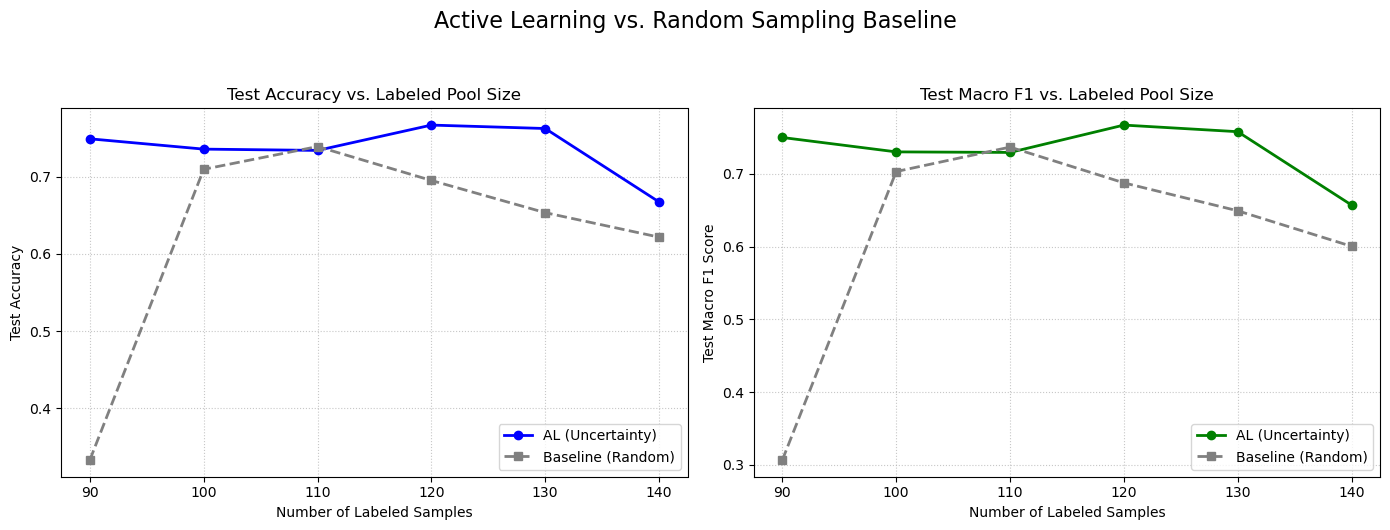


 PAPER REPORT: TEST SET PERFORMANCE COMPARISON
 Iteration  Labeled Samples Data Budget (%) Random Acc AL Acc Random F1  AL F1
         0               90           1.43%     0.3333 0.7489    0.3065 0.7501
         1              100           1.59%     0.7094 0.7356    0.7033 0.7303
         2              110           1.75%     0.7389 0.7339    0.7369 0.7296
         3              120           1.90%     0.6950 0.7667    0.6877 0.7672
         4              130           2.06%     0.6533 0.7622    0.6493 0.7581
         5              140           2.22%     0.6217 0.6672    0.6005 0.6572

[*] Metrics table saved to 'plots/metrics_comparison_table.csv'


In [ ]:
# ==========================================
# Plot Learning Curves
# ==========================================
def plot_learning_curves(al_history, random_history, save_dir='plots'):
    """Generates and saves learning curves comparing AL and Random sampling."""
    os.makedirs(save_dir, exist_ok=True)
    
    # Extract data for plotting
    al_samples = [x['labeled_samples'] for x in al_history]
    al_acc = [x['test_accuracy'] for x in al_history]
    al_f1 = [x['test_macro_f1'] for x in al_history]
    
    rand_samples = [x['labeled_samples'] for x in random_history]
    rand_acc = [x['test_accuracy'] for x in random_history]
    rand_f1 = [x['test_macro_f1'] for x in random_history]

    # Create a 1x2 subplot figure
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle('Active Learning vs. Random Sampling Baseline', fontsize=16, y=1.05)

    # Plot 1: Test Accuracy
    axes[0].plot(al_samples, al_acc, marker='o', linewidth=2, label='AL (Uncertainty)', color='blue')
    axes[0].plot(rand_samples, rand_acc, marker='s', linewidth=2, linestyle='--', label='Baseline (Random)', color='gray')
    axes[0].set_title('Test Accuracy vs. Labeled Pool Size')
    axes[0].set_xlabel('Number of Labeled Samples')
    axes[0].set_ylabel('Test Accuracy')
    axes[0].grid(True, linestyle=':', alpha=0.7)
    axes[0].legend()

    # Plot 2: Test Macro F1
    axes[1].plot(al_samples, al_f1, marker='o', linewidth=2, label='AL (Uncertainty)', color='green')
    axes[1].plot(rand_samples, rand_f1, marker='s', linewidth=2, linestyle='--', label='Baseline (Random)', color='gray')
    axes[1].set_title('Test Macro F1 vs. Labeled Pool Size')
    axes[1].set_xlabel('Number of Labeled Samples')
    axes[1].set_ylabel('Test Macro F1 Score')
    axes[1].grid(True, linestyle=':', alpha=0.7)
    axes[1].legend()

    plt.tight_layout()
    save_path = os.path.join(save_dir, 'learning_curves_comparison.png')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    print(f"[*] Learning curves saved to '{save_path}'")
    plt.show()

# ==========================================
# Generate Paper-Ready Tables (FIXED)
# ==========================================
def generate_metrics_table(al_history, random_history, total_train_pool=6300):
    """Combines metrics into a Pandas DataFrame for easy viewing and reporting."""
    table_data = []
    
    for i in range(len(al_history)):
        al_iter = al_history[i]
        rand_iter = random_history[i]
        
        # FIX: Calculate budget dynamically so we don't rely on the missing key in Iteration 0
        budget_pct = (al_iter['labeled_samples'] / total_train_pool) * 100
        
        row = {
            'Iteration': al_iter['iteration'],
            'Labeled Samples': al_iter['labeled_samples'],
            'Data Budget (%)': f"{budget_pct:.2f}%",
            'Random Acc': f"{rand_iter['test_accuracy']:.4f}",
            'AL Acc': f"{al_iter['test_accuracy']:.4f}",
            'Random F1': f"{rand_iter['test_macro_f1']:.4f}",
            'AL F1': f"{al_iter['test_macro_f1']:.4f}"
        }
        table_data.append(row)
        
    df = pd.DataFrame(table_data)
    
    print("\n" + "="*70)
    print(" PAPER REPORT: TEST SET PERFORMANCE COMPARISON")
    print("="*70)
    try:
        print(df.to_markdown(index=False))
    except ImportError:
        print(df.to_string(index=False))
    print("="*70 + "\n")
    
    return df

# ==========================================
# Execution Block
# ==========================================
if __name__ == "__main__":
    if 'al_metrics_history' not in locals() or 'random_metrics_history' not in locals():
        print("[!] Error: History lists not found in memory.")
    else:
        print("[*] Generating visual reports...")
        plot_learning_curves(al_metrics_history, random_metrics_history)
        
        comparison_df = generate_metrics_table(al_metrics_history, random_metrics_history)
        comparison_df.to_csv('plots/metrics_comparison_table.csv', index=False)
        print("[*] Metrics table saved to 'plots/metrics_comparison_table.csv'")